# Step 15: kinetic-map 3D encoder, self-supervised, fine-tuned with the clinical data (GPU T4, ~1.5-2.5 h)
**Model 2 of 2.** Only BreastDCEDL data (I-SPY1, I-SPY2, Duke). Step 13's SimCLR 3D encoder is the only image model
so far that added significantly to the clinical data (clinical + volume 0.696 -> 0.712 OOF, p = 0.028) and it
clearly beat the same network with random weights. It was trained on the v1 uint8 caches with the three phase
intensities as channels. This step keeps the idea and changes its input and its use:

| step 13 | here |
|---|---|
| v1 uint8 caches (clipped late phase) | best attached cache per cohort (raw > `mnj-cache-v2` > v1), mapped back to scanner units |
| channels = pre / early / late intensities (scanner dependent) | channels = **kinetic maps**: log pre-contrast, percent enhancement, washout (+ the tumour ROI). Ratios: the scanner gain cancels, so no intensity normalisation is needed |
| fixed crop around the tumour | **tumour-scale crop**: tumour box + 10 mm, resized to 32 x 64 x 64, so a 29 mm Duke tumour fills the input like a 65 mm I-SPY one (size goes in as a clinical input) |
| SimCLR, 150 epochs, then only a linear probe | SimCLR on every train + val patient incl. the unlabelled Duke patients (never test, D-012), up to 300 epochs; linear probe vs a **random-weight control** |
| | **fine-tuning** of the pretrained encoder, image only and with the clinical data fed in by **FiLM** (the clinical vector scales and shifts the image features), repeated outer CV with early stopping on an inner split; out-of-fold scores for every train patient |
| | `stack_inputs.csv` with the out-of-fold scores, for step 14's stack |

Numbers to beat (OOF): clinical 0.688, step 13 best 0.712; image only: step 13 SimCLR probe 0.582.

Kaggle setup: Accelerator **GPU T4 x2** (one GPU is used), Internet **ON**.
**+ Add Input**:
- the caches, best first: **`mnj-cache2-ispy1/-ispy2/-duke`** (raw), else **`mnj-cache-v2`**; v1 still works;
- the code: the `mnj-code-vaib` Dataset (the same version as for steps 11-13);
- optional: a previous step-15 output (`encoder_ssl.pt`) with `SSL_WEIGHTS = "auto"` and `RUN_SSL = False` to skip
  pretraining.

Run with `DEBUG = True` first (~150 patients, 3 SimCLR epochs, 1 short fine-tuning repeat: a few minutes), then
`DEBUG = False` with **Save Version -> Save & Run All (Commit)**. Every step prints a timestamped `[...]` line.
Results: Output tab, `results/<PERSON>/step15/`. Then attach this notebook's output to step 14.

In [1]:
# ==== PARAMETERS (edit these) ====
REPO = "AkulaReddy/MRI_chemo_response"
GIT_TAG = "vaib"           # branch (or tag) to clone
PERSON = ""               # optional: "A", "B" or "C" -> results/<PERSON>/ (empty -> results/vaib/)
STEP = "step15"
CACHE_ORDER = ["raw", "uint8_v2", "uint8_v1"]   # per cohort, the first kind attached that loads
CROP = (32, 64, 64)          # z, y, x of the tumour-scale crop
MARGIN_MM = 10.0             # tissue kept around the tumour box
ROI_CHANNEL = True           # 4th channel: the tumour ROI (same rule for every cohort)
USE_UNLABELED = True         # pretrain also on the train/val patients without a pCR label (Duke)
RUN_SSL = True
SSL_WEIGHTS = ""             # "auto": reuse an attached encoder_ssl.pt when RUN_SSL = False
SSL_EPOCHS = 300
SSL_BATCH = 96
SSL_MAX_MINUTES = 100
SSL_LR = 1e-3
TEMPERATURE = 0.1
WIDTH = 32                   # encoder width (feature size = 8 x WIDTH)
PROBE_REPEATS = 5            # repeated 5-fold CV for the linear probes
FT_MODES = ["film", "image"] # fine-tuning with the clinical data (FiLM) and image only
FT_REPEATS = 2               # outer CV repeats for fine-tuning (x 5 folds)
FT_EPOCHS = 40
FT_PATIENCE = 8
FT_BATCH = 32
LR_ENC, LR_HEAD = 1e-4, 1e-3
JOBS = 4
SEED = 0
EXTRA_PIP = []
TIME_BUDGET_H = 11.0
DEBUG = False                # True: ~150 patients, 3 SimCLR epochs, 1 fine-tuning repeat of 3 epochs
PUSH_RESULTS = False
NOTEBOOK_NAME = "step15"

In [2]:
# ==== SETUP (do not edit): get the repo code, install requirements ====
import base64, glob, json, os, shutil, subprocess, sys, zipfile
if PERSON not in ("A", "B", "C"):           # only names the results folder
    PERSON = "vaib"
    print('PERSON not set: results go to results/vaib/ (set PERSON = "A", "B" or "C" to change)')
NEEDS = "src/vitonly/rcv.py"               # the steps 11-13 code (in the mnj-code-vaib zip made on 2026-11-04 or later)
_tok = None
try:
    from kaggle_secrets import UserSecretsClient
    _tok = UserSecretsClient().get_secret("GITHUB_TOKEN")
except Exception as e:
    print("no GITHUB_TOKEN secret attached to this notebook (fine if the mnj-code-vaib Dataset is attached):",
          type(e).__name__)

def git(*args, cwd="/tmp/repo"):
    """git with the token as a one-off header (never stored in .git/config or the output)."""
    if not _tok:
        raise RuntimeError("no GITHUB_TOKEN secret: git push/pull is not available")
    hdr = "Authorization: Basic " + base64.b64encode(f"x-access-token:{_tok}".encode()).decode()
    r = subprocess.run(["git", "-c", f"http.extraHeader={hdr}", *args], cwd=cwd, capture_output=True, text=True)
    out = (r.stdout + r.stderr).replace(_tok, "***")
    if r.returncode:
        raise RuntimeError(f"git {args[0]} failed:\n{out}")
    return out

def _find_code():
    """An attached code Dataset that already has the steps 11-13 code (an unpacked folder or the uploaded zip)."""
    hits = [h for d in range(1, 8) for h in glob.glob("/kaggle/input/" + "*/" * d + NEEDS)]
    if not hits:
        for z in [z for d in range(1, 6) for z in glob.glob("/kaggle/input/" + "*/" * d + "mnj-code-vaib*.zip")]:
            zipfile.ZipFile(z).extractall("/tmp/code_zip")
        hits = glob.glob("/tmp/code_zip/**/" + NEEDS, recursive=True)
    return os.path.dirname(os.path.dirname(os.path.dirname(hits[0]))) if hits else None

shutil.rmtree("/tmp/repo", ignore_errors=True)
code_root = _find_code()
if code_root:                               # 1) the attached code Dataset with the new code wins
    shutil.copytree(code_root, "/tmp/repo")
    print("code: attached Dataset", code_root)
elif _tok:                                  # 2) or clone the branch from GitHub
    git("clone", "--quiet", "--depth", "1", "--branch", GIT_TAG, f"https://github.com/{REPO}.git", "/tmp/repo", cwd="/tmp")
    print("code: GitHub", REPO, GIT_TAG, git("log", "-1", "--format=%h %s"))
    if not os.path.exists(f"/tmp/repo/{NEEDS}"):
        raise SystemExit(f"branch {GIT_TAG} has no steps 11-13 code ({NEEDS}). Attach the NEW mnj-code-vaib zip "
                         "(+ Add Input -> Your Datasets -> mnj-code-vaib, latest version), or set GIT_TAG to a branch with it.")
else:
    print("attached inputs:")
    for root, dirs, files in os.walk("/kaggle/input"):
        if root.count("/") <= 5:
            print("  ", root, dirs[:6], files[:4])
        else:
            dirs[:] = []
    raise SystemExit(
        "\nThe notebook can't find the steps 11-13 code. Upload the new mnj-code-vaib.zip as a NEW VERSION of the\n"
        "mnj-code-vaib Dataset, then + Add Input -> Your Datasets -> mnj-code-vaib (latest version) and Run All again.")
os.chdir("/tmp/repo")
sys.path.insert(0, "/tmp/repo")         # so `from src...` works in this kernel
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-kaggle.txt"], check=True)
for pkg in EXTRA_PIP:                   # optional extras: a failed install is reported, never fatal
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], capture_output=True, text=True)
    print(f"pip install {pkg}:", "ok" if r.returncode == 0 else "FAILED (the step that needs it is skipped)\n" + r.stderr[-500:])
import torch; print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

PERSON not set: results go to results/vaib/ (set PERSON = "A", "B" or "C" to change)
no GITHUB_TOKEN secret attached to this notebook (fine if the mnj-code-vaib Dataset is attached): BackendError
code: attached Dataset /kaggle/input/datasets/a15chvaibhav/mnj-code-vaib/MRI_chemo_response
torch 2.11.0+cu130 | GPU: Tesla T4


In [3]:
# ==== HELPERS (do not edit): training runs, prediction files, comparisons ====
import glob, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import evaluation as ev, stats
from src.train import find_caches
from src.data.metadata import patient_table
COH = ["ispy1", "ispy2", "duke"]
OUT = f"/kaggle/working/results/{PERSON}/{STEP}"
os.makedirs(OUT, exist_ok=True)
T0 = time.time()
RUNS_JSON = {}
pd.set_option("display.width", 250, "display.max_columns", 40)

def budget_left():
    return TIME_BUDGET_H - (time.time() - T0) / 3600

def say(msg):
    """Timestamped progress line (elapsed and remaining budget), flushed so it shows in the Kaggle log at once."""
    el = (time.time() - T0) / 3600
    print(f"[{time.strftime('%H:%M:%S')} | {el:.2f} h elapsed, {budget_left():.2f} h left] {msg}", flush=True)

def run_cmd(cmd):
    """Run a training subprocess and stream its output line by line into this notebook (subprocess.run alone
    shows nothing until it ends, and the child's stdout is block-buffered without PYTHONUNBUFFERED)."""
    print("\n" + " ".join(cmd), flush=True)
    t = time.time()
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
                         env={**os.environ, "PYTHONUNBUFFERED": "1"})
    for line in p.stdout:
        print(line, end="", flush=True)
    if p.wait():
        raise subprocess.CalledProcessError(p.returncode, cmd)
    say(f"finished in {(time.time() - t) / 60:.1f} min")

def check_caches(version):
    caches = find_caches(["/kaggle/input", "/kaggle/working"])
    info = {c: json.load(open(f"{d}/cache_meta.json")).get("builder_version", 1) for c, d in caches.items()}
    print("caches:", {c: f"builder v{v}: {caches[c]}" for c, v in info.items()})
    if version is not None:
        bad = {c: v for c, v in info.items() if v != version}
        assert not bad and len(info) == 3, (f"need cache builder v{version} for all 3 cohorts (attach mnj-cache-v2); "
                                            f"found {info}")
    return caches

def _copy(d, label):
    os.makedirs(f"{OUT}/{label}", exist_ok=True)
    for f in ("val_preds.csv", "metrics.json", "log.csv", "config_resolved.yaml", "export_preds.csv",
              "train_preds.csv", "encoder.json"):
        if os.path.exists(f"{d}/{f}"):
            shutil.copy(f"{d}/{f}", f"{OUT}/{label}/{f}")

def train(config, seed, sets=(), label=None, cohorts=None):
    """One src.train run (B3 / F2 ...) -> (run_dir, metrics). Its small files are copied to OUT/<label>/."""
    cmd = [sys.executable, "-m", "src.train", "--config", config, "--seed", str(seed), "--out", "/kaggle/working/runs"]
    if CACHE_VERSION is not None: cmd += ["--cache-version", str(CACHE_VERSION)]
    if cohorts: cmd += ["--cohorts", *cohorts]
    if DEBUG: cmd.append("--debug")
    if sets: cmd += ["--set", *sets]
    run_cmd(cmd)
    d = max(glob.glob("/kaggle/working/runs/*/"), key=os.path.getmtime).rstrip("/")
    if label: _copy(d, label)
    return d, json.load(open(f"{d}/metrics.json"))

def finetune(config, seed, sets=(), label=None, cohorts=None):
    """One src.vitonly.finetune run (our pipeline: ViT-only vo_base / fusion vo_fusion) -> run_dir."""
    cmd = [sys.executable, "-m", "src.vitonly.finetune", "--config", config, "--seed", str(seed),
           "--cache-root", "/kaggle/input", "/kaggle/working", "--out", "/kaggle/working/runs"]
    if cohorts: cmd += ["--cohorts", *cohorts]
    if DEBUG: cmd.append("--debug")
    if sets: cmd += ["--set", *sets]
    run_cmd(cmd)
    d = max(glob.glob("/kaggle/working/runs/*/"), key=os.path.getmtime).rstrip("/")
    if label: _copy(d, label)
    return d

def note_runs(key, dirs):
    """label -> run folder names, in OUT/runs.json: step 8 uses it to find the checkpoints."""
    RUNS_JSON[key] = [os.path.basename(d) for d in dirs]
    json.dump(RUNS_JSON, open(f"{OUT}/runs.json", "w"), indent=1)

def preds_of(dirs):
    fr = [ev.load_preds(f"{d}/val_preds.csv") for d in dirs]
    return fr[0] if len(fr) == 1 else ev.ensemble(fr)

def save_preds(label, df):
    os.makedirs(f"{OUT}/{label}", exist_ok=True)
    df.to_csv(f"{OUT}/{label}/val_preds.csv", index=False)
    return df

def repo_preds(pattern):
    hits = sorted(glob.glob(f"results/*/{pattern}/val_preds.csv"))
    return preds_of([os.path.dirname(h) for h in hits]) if hits else None

def train_auc(d):
    """AUC on the training patients from export_preds.csv (B3 exports after training): the overfitting gap."""
    f = f"{d}/export_preds.csv"
    if not os.path.exists(f): return np.nan
    e = pd.read_csv(f); e = e[e.split == "train"]
    return stats.auc(e.label, e.prob)

def vo_train_auc(d):
    """Training-set AUC of a src.vitonly run (metrics.json): the overfitting gap."""
    return json.load(open(f"{d}/metrics.json"))["val"].get("train_auc", np.nan)

def compare(preds, ref):
    """One row per model on the patients all models share: AUC (DeLong CI), AUPRC, Brier, ECE, the 90%-spec
    operating point (threshold chosen on these same val patients: optimistic), and the paired DeLong test
    and paired bootstrap of the AUC difference vs `ref`."""
    preds = ev.align({k: v for k, v in preds.items() if v is not None})
    rows = []
    for k, d in preds.items():
        r = {"model": k, **ev.summary_row(d.label, d.prob)}
        if k != ref and ref in preds:
            y = preds[ref].label
            dl = ev.delong(y, preds[ref].prob, d.prob)
            pb = stats.paired_bootstrap_auc_diff(y, preds[ref].prob, d.prob)
            r.update(diff_vs_ref=dl["diff"], delong_ci_lo=dl["ci"][0], delong_ci_hi=dl["ci"][1], delong_p=dl["p"],
                     boot_p=pb["p"])
        rows.append(r)
    cols = ["model", "n", "pcr", "auc", "ci_lo", "ci_hi", "auprc", "brier", "ece", "sens@90spec", "ppv@90spec",
            "npv@90spec", "diff_vs_ref", "delong_ci_lo", "delong_ci_hi", "delong_p", "boot_p"]
    t = pd.DataFrame(rows)
    return t[[c for c in cols if c in t]]

def subtype_wide(preds, by="subtype"):
    """AUC (95% CI) per subtype (or cohort) for every model, all on the same patients; n / pCR+ per group."""
    preds = ev.align({k: v for k, v in preds.items() if v is not None})
    tabs = {k: ev.subgroup_table(d, by).set_index(by) for k, d in preds.items()}
    first = next(iter(tabs.values()))
    out = pd.DataFrame({"n": first.n.astype(int), "pCR+": first.pcr.astype(int)})
    for k, t in tabs.items():
        out[k] = [f"{a:.3f} ({lo:.2f}-{hi:.2f})" if a == a else "n/a (one class)"
                  for a, lo, hi in zip(t.auc, t.ci_lo, t.ci_hi)]
    return out

B1_VAL = repo_preds("b1_lr_s0_*")                       # clinical + tumour size, logistic regression (val 0.653)
B0_VAL = repo_preds("b0_lr_s0_*")                       # clinical only (val 0.639)
AKULA_B3_V2 = repo_preds("b3_vit_s0_1019-0302_*")       # Akula's B3 on cache v2 (val 0.559)
B3_V1 = repo_preds("b3_vit_s0_1009-1616_*")             # B3 on the old cache (val 0.530)
F2_V1 = repo_preds("f2_attn_s0_1009-1605_*")            # fusion on the old cache (val 0.690)
print("reference predictions from the repo:", {k: v is not None for k, v in
      dict(B1=B1_VAL, B0=B0_VAL, B3_v2_Akula=AKULA_B3_V2, B3_v1=B3_V1, F2_v1=F2_V1).items()})

reference predictions from the repo: {'B1': True, 'B0': True, 'B3_v2_Akula': True, 'B3_v1': True, 'F2_v1': True}


In [4]:
# ==== the code of this step is written to /tmp/mnjlib by the next cells (the repo itself is not changed) ====
LIB = "/tmp/mnjlib"
os.makedirs(LIB, exist_ok=True)
if LIB not in sys.path:
    sys.path.insert(0, LIB)
os.environ["PYTHONPATH"] = os.pathsep.join([LIB, "/tmp/repo", os.environ.get("PYTHONPATH", "")])
os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning,ignore::UserWarning"   # also for the worker processes
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [5]:
%%writefile /tmp/mnjlib/mnj_common.py
"""Shared code for steps 14 and 15 (BreastDCEDL only: I-SPY1, I-SPY2, Duke caches + the metadata CSV).

- caches: find the attached caches, pick the best kind per cohort, load one patient as float phases
- tumour ROI: shipped I-SPY mask, or one enhancement rule used for every cohort
- metrics: AUC, within-group AUC, bootstrap CI, paired bootstrap
- repeated stratified CV for scikit-learn models, with ComBat fitted inside each fold
"""
from __future__ import annotations

import json
import os
import time

import numpy as np
import pandas as pd
from scipy import ndimage as ndi
from scipy.stats import rankdata

COH = ("ispy1", "ispy2", "duke")
SUBTYPE = {"HRposHER2neg": "HR+/HER2-", "HER2pos": "HER2+", "TripleNeg": "TN"}


def log(tag, msg):
    print(f"[{tag} {time.strftime('%H:%M:%S')}] {msg}", flush=True)


# ----------------------------------------------------------------------------- metadata
def load_meta(repo="/tmp/repo"):
    """Metadata of all 2,070 patients with cohort / split / labeled / log_bbox_vol / subtype."""
    try:
        import sys
        if repo not in sys.path:
            sys.path.insert(0, repo)
        from src.data.metadata import load_metadata
        m = load_metadata()
    except Exception as e:  # noqa: BLE001
        print("load_metadata() failed, reading the CSV directly:", type(e).__name__, e)
        m = pd.read_csv(f"{repo}/data/metadata/BreastDCEDL_metadata_min_crop.csv")
        m["cohort"] = m.dataset.map({"spy1": "ispy1", "spy2": "ispy2", "duke": "duke"})
        m["split"] = m["test"].astype(int).map({0: "train", 2: "val", 1: "test"})
        m["labeled"] = m.pCR.notna()
        dz = (m.mask_end - m.mask_start).clip(lower=1)
        dy = (m.eraw - m.sraw).clip(lower=1)
        dx = (m.ecol - m.scol).clip(lower=1)
        m["bbox_vol_mm3"] = dz * m.slice_thick * dy * dx * m.xy_spacing ** 2
        m["log_bbox_vol"] = np.log(m.bbox_vol_mm3)
        m = m.set_index("pid", drop=False).rename_axis(None)
    m["pid"] = m["pid"].astype(str)
    m["subtype"] = m["HR_HER2_STATUS"].map(SUBTYPE)
    return m


def clinical_frame(meta):
    """The clinical inputs every earlier model used (D-008): HR, HER2, age, menopause, race, + HR x HER2.
    NaN = missing (the linear models add a missing indicator; the boosted trees use NaN directly)."""
    num = lambda c: pd.to_numeric(meta[c], errors="coerce")  # noqa: E731
    d = pd.DataFrame(index=meta.index)
    d["clin_HR"] = num("HR")
    d["clin_HER2"] = num("HER2")
    d["clin_HRxHER2"] = d.clin_HR * d.clin_HER2
    d["clin_age"] = num("age")
    d["clin_menopause"] = num("menopause")
    w, b = num("race_white"), num("race_black")
    d["clin_race_black"] = b
    d["clin_race_other"] = ((w == 0) & (b == 0)).astype(float).where(w.notna() & b.notna())
    return d


# ----------------------------------------------------------------------------- caches
def _first_npz(d, limit=2000):
    try:
        with os.scandir(d) as it:
            for i, e in enumerate(it):
                if e.name.endswith(".npz"):
                    return e.path
                if i > limit:
                    break
    except OSError:
        pass
    return None


def _cohort_of(d, meta_json):
    c = meta_json.get("cohort")
    if c in COH:
        return c
    low = d.lower()
    for c in ("ispy1", "ispy2", "duke"):
        if c in low:
            return c
    return None


def cache_kind(d):
    """'raw' (float phases, nothing clipped), 'uint8_v2' (0.7 mm, tumour clip) or 'uint8_v1' (native, clipped)."""
    meta = {}
    if os.path.exists(f"{d}/cache_meta.json"):
        try:
            meta = json.load(open(f"{d}/cache_meta.json"))
        except Exception:  # noqa: BLE001
            meta = {}
    f = _first_npz(d)
    if f is None:
        return None, meta
    with np.load(f) as z:
        if "rgb" in z.files and z["rgb"].dtype == np.uint8:
            return f"uint8_v{int(meta.get('builder_version', 1) or 1)}", meta
    return "raw", meta


def find_caches(roots=("/kaggle/input", "/kaggle/working"), order=("raw", "uint8_v2", "uint8_v1"), max_depth=7,
                meta=None):
    """{cohort: {"dir", "kind", "index"}}: per cohort the first kind in `order` whose first patient loads."""
    cands = {c: [] for c in COH}
    for root in roots:
        if not os.path.isdir(root):
            continue
        for dirpath, dirs, files in os.walk(root, followlinks=True):
            if dirpath[len(root):].count(os.sep) >= max_depth or "/results/" in dirpath + "/":
                dirs[:] = []
                continue
            if "cache_meta.json" in files or "cache_index.csv" in files:
                kind, mj = cache_kind(dirpath)
                coh = _cohort_of(dirpath, mj)
                if kind and coh:
                    cands[coh].append((kind, dirpath))
                dirs[:] = []
    out = {}
    for c in COH:
        ranked = sorted(cands[c], key=lambda kd: order.index(kd[0]) if kd[0] in order else 99)
        for kind, d in ranked:
            idx = read_index(d)
            f = _first_npz(d)
            try:
                pid = os.path.basename(f)[:-4]
                row = meta.loc[pid] if meta is not None and pid in meta.index else None
                load_case(f, row, clip_of(idx, pid))
            except Exception as e:  # noqa: BLE001
                print(f"  {c}: {kind} cache at {d} does not load ({type(e).__name__}: {e}); trying the next one")
                continue
            out[c] = {"dir": d, "kind": kind, "index": idx}
            break
    return out


def read_index(d):
    p = f"{d}/cache_index.csv"
    if not os.path.exists(p):
        return None
    idx = pd.read_csv(p, dtype={"pid": str})
    return idx.set_index("pid", drop=False)


def clip_of(idx, pid):
    if idx is None or pid not in idx.index or "clip_lo" not in idx.columns:
        return None
    lo, hi = idx.loc[pid, "clip_lo"], idx.loc[pid, "clip_hi"]
    if isinstance(lo, pd.Series):
        lo, hi = lo.iloc[0], hi.iloc[0]
    return (float(lo), float(hi)) if pd.notna(lo) and pd.notna(hi) else None


def cache_files(caches, pids):
    """{pid: (cohort, path)} for the pids that have an npz in their cohort's chosen cache."""
    out = {}
    for c, info in caches.items():
        have = {f[:-4] for f in os.listdir(info["dir"]) if f.endswith(".npz")}
        for p in pids:
            if p in have:
                out[p] = (c, os.path.join(info["dir"], p + ".npz"))
    return out


def load_case(path, meta_row=None, clip=None):
    """One cached patient -> dict(pre, early, late float32 (S, H, W); mask bool or None; t0, t1; bbox (y0, y1,
    x0, x1); dz, dxy mm; sat bool (S, H, W) or None; clip_known). uint8 caches are mapped back to scanner units
    with the patient's clip range (npz `clip`, else cache_index.csv), so ratios such as PE are meaningful."""
    with np.load(path, allow_pickle=False) as z:
        k = set(z.files)
        phases, sat, clip_known = None, None, True
        if "rgb" in k:
            a = z["rgb"]
            if a.dtype == np.uint8:
                lohi = tuple(float(v) for v in z["clip"][:2]) if "clip" in k else clip
                clip_known = lohi is not None
                lo, hi = lohi if lohi is not None else (0.0, 255.0)
                sat = (a == 255).any(-1)
                phases = a.astype(np.float32) * np.float32((hi - lo) / 255.0) + np.float32(lo)
            else:
                phases = a.astype(np.float32)
        else:   # raw caches: find the (S, H, W, 3) / (3, S, H, W) array or three named phase arrays
            for key in sorted(k):
                v = z[key]
                if v.ndim == 4 and v.shape[-1] == 3:
                    phases = v.astype(np.float32)
                    break
                if v.ndim == 4 and v.shape[0] == 3:
                    phases = np.moveaxis(v, 0, -1).astype(np.float32)
                    break
            if phases is None:
                for names in (("pre", "early", "late"), ("p0", "p1", "p2"), ("phase0", "phase1", "phase2")):
                    if all(n in k for n in names):
                        phases = np.stack([z[n] for n in names], -1).astype(np.float32)
                        break
        if phases is None:
            raise KeyError(f"{os.path.basename(path)}: unknown cache format, keys {sorted(k)}")
        S, H, W = phases.shape[:3]
        mask = z["mask"].astype(bool) if "mask" in k else None
        if mask is not None and mask.shape != (S, H, W):
            mask = None
        if "t0" in k and "t1" in k:
            t0, t1 = int(z["t0"]), int(z["t1"])
        elif mask is not None and mask.any():
            zz = np.where(mask.any((1, 2)))[0]
            t0, t1 = int(zz[0]), int(zz[-1]) + 1
        else:
            raise KeyError(f"{os.path.basename(path)}: no t0/t1 and no mask to locate the tumour")
        if "bbox" in k:
            y0, y1, x0, x1 = (int(v) for v in np.asarray(z["bbox"]).ravel()[:4])
        elif mask is not None and mask.any():
            yy, xx = np.where(mask.any(0))
            y0, y1, x0, x1 = int(yy.min()), int(yy.max()) + 1, int(xx.min()), int(xx.max()) + 1
        else:
            raise KeyError(f"{os.path.basename(path)}: no bbox and no mask")
        if "spacing" in k:
            sp = np.asarray(z["spacing"], float).ravel()
            dz, dxy = float(sp[0]), float(sp[-1])
        elif meta_row is not None:
            dz = float(meta_row["slice_thick"])
            n_xy, dxy = float(meta_row["n_xy"]), float(meta_row["xy_spacing"])
            if n_xy < 256:
                dxy *= n_xy / 256.0
        else:
            dz, dxy = 2.0, 0.7
    t0, t1 = max(0, min(t0, S - 1)), max(1, min(t1, S))
    t1 = max(t1, t0 + 1)
    y0, y1 = max(0, y0), min(H, max(y1, y0 + 1))
    x0, x1 = max(0, x0), min(W, max(x1, x0 + 1))
    return dict(pre=phases[..., 0], early=phases[..., 1], late=phases[..., 2], mask=mask, t0=t0, t1=t1,
                bbox=(y0, y1, x0, x1), dz=dz, dxy=dxy, sat=sat, clip_known=clip_known)


# ----------------------------------------------------------------------------- tumour ROI
def ref_intensity(pre, t0, t1):
    """Robust bright level of the pre-contrast tumour slices (99th percentile of tissue)."""
    v = pre[t0:t1]
    v = v[v > 0]
    return float(np.percentile(v, 99)) if v.size else 1.0


def pe_map(pre, post, floor):
    return (post - pre) / np.maximum(pre, floor)


def rule_roi(pre, early, t0, t1, bbox, pe_thr=0.7, pad=2, min_vox=20):
    """One rule for every cohort (FTV-style, as the I-SPY masks were made): inside the tumour box (+pad px)
    and the tumour slices, tissue (pre > 5% of the bright level) enhancing by >= pe_thr; the largest 3D
    component, holes filled per slice. Relaxed threshold, then an inscribed ellipsoid, as fallbacks."""
    S, H, W = pre.shape
    y0, y1, x0, x1 = bbox
    y0, x0, y1, x1 = max(0, y0 - pad), max(0, x0 - pad), min(H, y1 + pad), min(W, x1 + pad)
    ref = ref_intensity(pre, t0, t1)
    floor = 0.05 * ref
    p, e = pre[t0:t1, y0:y1, x0:x1], early[t0:t1, y0:y1, x0:x1]
    pe = pe_map(p, e, floor)
    method = "rule"
    m = (p > floor) & (pe >= pe_thr)
    if m.sum() < min_vox:
        m, method = (p > floor) & (pe >= pe_thr / 2), "rule_relaxed"
    if m.sum() >= min_vox:
        lab, n = ndi.label(m)
        if n > 1:
            sizes = ndi.sum(m, lab, range(1, n + 1))
            m = lab == (1 + int(np.argmax(sizes)))
        m = np.stack([ndi.binary_fill_holes(s) for s in m])
    if m.sum() < min_vox:
        zz, yy, xx = np.ogrid[:t1 - t0, :y1 - y0, :x1 - x0]
        cz, cy, cx = (t1 - t0 - 1) / 2, (y1 - y0 - 1) / 2, (x1 - x0 - 1) / 2
        rz, ry, rx = max(cz, 0.5) + 0.5, max(cy, 0.5) + 0.5, max(cx, 0.5) + 0.5
        m = ((zz - cz) / rz) ** 2 + ((yy - cy) / ry) ** 2 + ((xx - cx) / rx) ** 2 <= 1
        method = "ellipsoid"
    full = np.zeros((S, H, W), bool)
    full[t0:t1, y0:y1, x0:x1] = m
    return full, method


def dice(a, b):
    s = a.sum() + b.sum()
    return float(2 * (a & b).sum() / s) if s else np.nan


# ----------------------------------------------------------------------------- metrics
def auc(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    ok = ~(np.isnan(y) | np.isnan(p))
    y, p = y[ok], p[ok]
    npos, nneg = (y == 1).sum(), (y == 0).sum()
    if npos == 0 or nneg == 0:
        return np.nan
    r = rankdata(p)
    return float((r[y == 1].sum() - npos * (npos + 1) / 2) / (npos * nneg))


def within_auc(y, p, groups):
    """AUC over the positive-negative pairs of the same group only (pairs across groups are ignored)."""
    y, p, g = np.asarray(y, float), np.asarray(p, float), pd.Series(groups).to_numpy()
    num = den = 0.0
    for v in pd.unique(g[pd.notna(g)]):
        s = g == v
        npos, nneg = (y[s] == 1).sum(), (y[s] == 0).sum()
        if npos and nneg:
            num += auc(y[s], p[s]) * npos * nneg
            den += npos * nneg
    return float(num / den) if den else np.nan


def boot_ci(y, p, n=2000, seed=0):
    y, p = np.asarray(y, float), np.asarray(p, float)
    rng = np.random.default_rng(seed)
    vals = [auc(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    vals = np.array([v for v in vals if v == v])
    return (float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))) if len(vals) else (np.nan, np.nan)


def paired_boot(y, pa, pb, n=2000, seed=0):
    """AUC(b) - AUC(a) on the same patients: difference, 95% CI, two-sided bootstrap p."""
    y, pa, pb = np.asarray(y, float), np.asarray(pa, float), np.asarray(pb, float)
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        d.append(auc(y[i], pb[i]) - auc(y[i], pa[i]))
    d = np.array([v for v in d if v == v])
    diff = auc(y, pb) - auc(y, pa)
    p = float(min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))) if len(d) else np.nan
    return {"diff": diff, "lo": float(np.percentile(d, 2.5)), "hi": float(np.percentile(d, 97.5)), "p": p}


def metric_row(frame, prob, prefix):
    """AUC, within-subtype, within-cohort and per-cohort AUC of `prob` on `frame` (pid, label, cohort, subtype)."""
    y = frame.label.to_numpy(float)
    r = {f"{prefix}_auc": auc(y, prob),
         f"{prefix}_within_subtype": within_auc(y, prob, frame.subtype),
         f"{prefix}_within_cohort": within_auc(y, prob, frame.cohort)}
    for c in COH:
        s = (frame.cohort == c).to_numpy()
        r[f"{prefix}_{c}"] = auc(y[s], np.asarray(prob)[s])
    return r


def md_table(df, digits=3):
    d = df.copy()
    for c in d.columns:
        if pd.api.types.is_float_dtype(d[c]):
            d[c] = d[c].map(lambda v: "" if pd.isna(v) else f"{v:.{digits}f}")
    cols = list(d.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in d.itertuples(index=False)]
    return "\n".join(lines)


# ----------------------------------------------------------------------------- ComBat
class ComBat:
    """Location/scale ComBat (Johnson 2007, without the empirical-Bayes shrinkage: every batch has >= ~80
    patients). Fitted on training patients only; covariates (HR, HER2) are protected; NaNs stay NaN."""

    def fit(self, X, batch, covars):
        X = np.asarray(X, float)
        self.med = np.nanmedian(X, 0)
        self.med = np.where(np.isnan(self.med), 0.0, self.med)
        Xf = np.where(np.isnan(X), self.med, X)
        self.levels = sorted(pd.unique(pd.Series(batch).astype(str)))
        B = self._onehot(batch)
        C = np.asarray(covars, float)
        self.cmean = np.nanmean(C, 0) if C.size else np.zeros(0)
        C = np.where(np.isnan(C), self.cmean, C) if C.size else C
        D = np.hstack([B, C]) if C.size else B
        beta, *_ = np.linalg.lstsq(D, Xf, rcond=None)
        nb = B.sum(0)
        self.alpha = (nb / nb.sum()) @ beta[:B.shape[1]]
        self.beta_c = beta[B.shape[1]:]
        resid = Xf - D @ beta
        self.sigma = np.sqrt((resid ** 2).mean(0)) + 1e-8
        Z = (Xf - self.alpha - (C @ self.beta_c if C.size else 0)) / self.sigma
        self.gamma = np.vstack([Z[B[:, j] == 1].mean(0) for j in range(B.shape[1])])
        self.delta = np.vstack([Z[B[:, j] == 1].var(0) + 1e-6 for j in range(B.shape[1])])
        return self

    def _onehot(self, batch):
        b = pd.Series(batch).astype(str).to_numpy()
        return np.stack([(b == lv).astype(float) for lv in self.levels], 1)

    def transform(self, X, batch, covars):
        X = np.asarray(X, float)
        nan = np.isnan(X)
        Xf = np.where(nan, self.med, X)
        C = np.asarray(covars, float)
        C = np.where(np.isnan(C), self.cmean, C) if C.size else C
        cov = C @ self.beta_c if C.size else 0
        Z = (Xf - self.alpha - cov) / self.sigma
        B = self._onehot(batch)
        known = B.sum(1) > 0
        g = B @ self.gamma
        dl = np.where(known[:, None], B @ self.delta, 1.0)
        Z = (Z - g) / np.sqrt(dl)
        out = Z * self.sigma + self.alpha + cov
        out[nan] = np.nan
        return out


# ----------------------------------------------------------------------------- repeated CV
def make_folds(strat, repeats, k=5, seed=0):
    from sklearn.model_selection import StratifiedKFold
    strat = np.asarray(strat)
    out = []
    for r in range(repeats):
        skf = StratifiedKFold(k, shuffle=True, random_state=seed + 1000 * r)
        for f, (tr, te) in enumerate(skf.split(np.zeros(len(strat)), strat)):
            out.append((r, f, tr, te))
    return out


def make_model(kind, seed=0, use_catboost=True):
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegressionCV
    from sklearn.model_selection import StratifiedKFold
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    if kind == "lr":
        return Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                         ("sc", StandardScaler()),
                         ("lr", LogisticRegressionCV(Cs=np.logspace(-3, 1, 9), scoring="roc_auc", max_iter=5000,
                                                     cv=StratifiedKFold(3, shuffle=True, random_state=seed)))])
    if kind == "gbm":
        if use_catboost:
            try:
                from catboost import CatBoostClassifier
                return CatBoostClassifier(depth=4, iterations=500, learning_rate=0.03, l2_leaf_reg=8,
                                          rsm=0.5, random_seed=seed, verbose=0, thread_count=1,
                                          allow_writing_files=False)
            except ImportError:
                pass
        from sklearn.ensemble import HistGradientBoostingClassifier
        return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.03, max_iter=300, min_samples_leaf=30,
                                              l2_regularization=3.0, early_stopping=False, random_state=seed)
    raise ValueError(kind)


def _fit_predict(kind, Xtr, ytr, Xte_list, seed, use_catboost):
    import warnings
    warnings.filterwarnings("ignore", category=FutureWarning)
    warnings.filterwarnings("ignore", category=UserWarning)
    m = make_model(kind, seed, use_catboost)
    m.fit(Xtr, ytr)
    return [m.predict_proba(X)[:, 1] for X in Xte_list]


def _harmonise(Xtr, Xte_list, combat_idx, btr, bte_list, ctr, cte_list):
    if combat_idx is None or not len(combat_idx):
        return Xtr, Xte_list
    Xtr = Xtr.copy()
    cb = ComBat().fit(Xtr[:, combat_idx], btr, ctr)
    Xtr[:, combat_idx] = cb.transform(Xtr[:, combat_idx], btr, ctr)
    out = []
    for X, b, c in zip(Xte_list, bte_list, cte_list):
        X = X.copy()
        X[:, combat_idx] = cb.transform(X[:, combat_idx], b, c)
        out.append(X)
    return Xtr, out


def _fold_job(X, y, tr, te, kinds, combat_idx, batch, covars, seed, use_catboost):
    Xtr, (Xte,) = _harmonise(X[tr], [X[te]], combat_idx, batch[tr], [batch[te]], covars[tr], [covars[te]])
    return {k: _fit_predict(k, Xtr, y[tr], [Xte], seed, use_catboost)[0] for k in kinds}


def cv_and_refit(X, y, folds, Xval, kinds=("lr", "gbm"), combat_idx=None, batch=None, covars=None,
                 batch_val=None, covars_val=None, seed=0, jobs=4, use_catboost=True):
    """Repeated CV on the training patients + one refit on all of them scored on val.
    Returns {kind: {"oof": (n,) mean over repeats, "fold_auc": [...], "val": (n_val,)}} plus "ens" =
    mean of the kinds' probabilities."""
    from joblib import Parallel, delayed
    X, y = np.asarray(X, float), np.asarray(y, int)
    n = len(y)
    batch = np.asarray(batch if batch is not None else np.zeros(n), object)
    covars = np.asarray(covars if covars is not None else np.zeros((n, 0)), float)
    res = Parallel(n_jobs=jobs)(delayed(_fold_job)(X, y, tr, te, kinds, combat_idx, batch, covars,
                                                   seed + 7 * r + f, use_catboost) for r, f, tr, te in folds)
    repeats = max(r for r, *_ in folds) + 1
    out = {}
    for k in list(kinds) + ["ens"]:
        oof = np.full((repeats, n), np.nan)
        fa = []
        for (r, f, tr, te), pr in zip(folds, res):
            p = np.mean([pr[kk] for kk in kinds], 0) if k == "ens" else pr[k]
            oof[r, te] = p
            fa.append(auc(y[te], p))
        out[k] = {"oof": np.nanmean(oof, 0), "fold_auc": fa}
    bv = np.asarray(batch_val if batch_val is not None else np.zeros(len(Xval)), object)
    cv = np.asarray(covars_val if covars_val is not None else np.zeros((len(Xval), 0)), float)
    Xtr, (Xv,) = _harmonise(X, [np.asarray(Xval, float)], combat_idx, batch, [bv], covars, [cv])
    vals = {k: _fit_predict(k, Xtr, y, [Xv], seed, use_catboost)[0] for k in kinds}
    for k in kinds:
        out[k]["val"] = vals[k]
    out["ens"]["val"] = np.mean([vals[k] for k in kinds], 0)
    return out

Writing /tmp/mnjlib/mnj_common.py


In [6]:
%%writefile /tmp/mnjlib/m2_data.py
"""Step 15 data: one tumour-centred 3D crop per patient, as kinetic maps (numpy only, runs in worker processes).

Channels (scanner gain cancels in every ratio, so no intensity normalisation is needed):
  0 logpre  log(1 + pre / bright level of the pre-contrast tumour slices)
  1 pe      percent enhancement (early - pre) / pre, clipped to [-0.5, 4]
  2 wash    (early - late) / |early - pre| where the tissue enhances (PE > 0.3), clipped to [-1.5, 1.5]
            (> 0 washout, ~0 plateau, < 0 persistent)
  3 roi     the tumour ROI from one rule for every cohort (optional)
The crop is the tumour box + a margin, made square in-plane, resized to a fixed grid (e.g. 32 x 64 x 64), so a
small Duke tumour fills the input as much as a large I-SPY one; absolute size goes in as a clinical input.
"""
from __future__ import annotations

import math

import numpy as np
from scipy import ndimage as ndi

import mnj_common as mc

CHANNELS = ("logpre", "pe", "wash", "roi")


def resize3d(a, shape):
    """Linear resampling of a (Z, Y, X) array to `shape` (cell-centred grids)."""
    coords = [(np.arange(o) + 0.5) * (i / o) - 0.5 for i, o in zip(a.shape, shape)]
    grid = np.meshgrid(*coords, indexing="ij")
    return ndi.map_coordinates(a.astype(np.float32), grid, order=1, mode="nearest").astype(np.float32)


def make_crop(pid, cohort, path, meta_row, clip=None, shape=(32, 64, 64), margin_mm=10.0, roi_channel=True,
              pe_thr=0.7):
    out = {"pid": pid, "cohort": cohort}
    try:
        c = mc.load_case(path, meta_row, clip)
        pre, early, late = c["pre"], c["early"], c["late"]
        S, H, W = pre.shape
        t0, t1 = c["t0"], c["t1"]
        y0, y1, x0, x1 = c["bbox"]
        roi, method = mc.rule_roi(pre, early, t0, t1, c["bbox"], pe_thr)
        ref = mc.ref_intensity(pre, t0, t1)
        floor = 0.1 * ref
        mz, mxy = int(math.ceil(margin_mm / c["dz"])), int(math.ceil(margin_mm / c["dxy"]))
        z0, z1 = max(0, t0 - mz), min(S, t1 + mz)
        side = max(y1 - y0, x1 - x0) + 2 * mxy
        ya, xa = int(round((y0 + y1) / 2 - side / 2)), int(round((x0 + x1) / 2 - side / 2))

        def take(v):
            o = np.zeros((z1 - z0, side, side), np.float32)
            sy0, sy1, sx0, sx1 = max(0, ya), min(H, ya + side), max(0, xa), min(W, xa + side)
            if sy1 > sy0 and sx1 > sx0:
                o[:, sy0 - ya:sy1 - ya, sx0 - xa:sx1 - xa] = v[z0:z1, sy0:sy1, sx0:sx1]
            return o

        P, E, L, R = take(pre), take(early), take(late), take(roi.astype(np.float32))
        pe = np.clip((E - P) / np.maximum(P, floor), -0.5, 4.0)
        wash = np.where(pe > 0.3, np.clip((E - L) / np.maximum(np.abs(E - P), floor), -1.5, 1.5), 0.0)
        logpre = np.log1p(np.maximum(P, 0) / ref)
        chans = [logpre, pe, wash] + ([R] if roi_channel else [])
        x = np.stack([resize3d(ch, shape) for ch in chans]).astype(np.float16)
        out.update(x=x, status="ok", roi_method=method, crop_side_mm=side * c["dxy"], crop_z_mm=(z1 - z0) * c["dz"],
                   roi_vox=int(roi.sum()), clip_known=c["clip_known"])
    except Exception as e:  # noqa: BLE001
        out.update(status="error", note=f"{type(e).__name__}: {e}")
    return out

Writing /tmp/mnjlib/m2_data.py


In [7]:
%%writefile /tmp/mnjlib/m2_net.py
"""Step 15 networks: small 3D ResNet encoder, GPU augmentation, SimCLR pretraining, embeddings, and
fine-tuning with the clinical data fed in by FiLM (feature-wise scale and shift of the image features)."""
from __future__ import annotations

import copy
import math
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

import mnj_common as mc


# ----------------------------------------------------------------------------- encoder
class Block(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.c1 = nn.Conv3d(cin, cout, 3, stride, 1, bias=False)
        self.b1 = nn.BatchNorm3d(cout)
        self.c2 = nn.Conv3d(cout, cout, 3, 1, 1, bias=False)
        self.b2 = nn.BatchNorm3d(cout)
        self.sc = None if (cin == cout and stride == 1) else nn.Sequential(
            nn.Conv3d(cin, cout, 1, stride, bias=False), nn.BatchNorm3d(cout))

    def forward(self, x):
        h = F.relu(self.b1(self.c1(x)), inplace=True)
        h = self.b2(self.c2(h))
        return F.relu(h + (x if self.sc is None else self.sc(x)), inplace=True)


class Encoder(nn.Module):
    """(B, C, 32, 64, 64) -> (B, 8w). Stem halves the in-plane size; then 32^3 -> 16^3 -> 8^3 -> 4^3."""

    def __init__(self, cin=4, w=32):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv3d(cin, w, (3, 5, 5), (1, 2, 2), (1, 2, 2), bias=False),
                                  nn.BatchNorm3d(w), nn.ReLU(inplace=True))
        self.layers = nn.Sequential(Block(w, w, 1), Block(w, 2 * w, 2), Block(2 * w, 4 * w, 2), Block(4 * w, 8 * w, 2))
        self.dim = 8 * w

    def forward(self, x):
        return F.adaptive_avg_pool3d(self.layers(self.stem(x)), 1).flatten(1)


# ----------------------------------------------------------------------------- augmentation (on the GPU)
def augment(x, strength=1.0):
    """Random flips, in-plane rotation, zoom, shift; gain jitter on log-pre, small jitter on the kinetic maps,
    noise. x: (B, C, Z, Y, X); channel 3 (ROI) follows the geometry only."""
    x = x.float().clone()
    B, C = x.shape[:2]
    dev = x.device
    for d in (2, 3, 4):
        m = torch.rand(B, device=dev) < 0.5
        if m.any():
            x[m] = x[m].flip(d)
    ang = (torch.rand(B, device=dev) * 2 - 1) * math.radians(20 * strength)
    sc = 1 - torch.rand(B, device=dev) * 0.25 * strength
    theta = torch.zeros(B, 3, 4, device=dev)
    theta[:, 0, 0], theta[:, 0, 1] = torch.cos(ang) * sc, -torch.sin(ang) * sc
    theta[:, 1, 0], theta[:, 1, 1] = torch.sin(ang) * sc, torch.cos(ang) * sc
    theta[:, 2, 2] = sc
    theta[:, :, 3] = (torch.rand(B, 3, device=dev) * 2 - 1) * 0.08 * strength
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    k = min(C, 3)
    x[:, 0:1] = x[:, 0:1] * (1 + (torch.rand(B, 1, 1, 1, 1, device=dev) * 2 - 1) * 0.15 * strength)
    if k > 1:
        x[:, 1:k] = x[:, 1:k] * (1 + (torch.rand(B, k - 1, 1, 1, 1, device=dev) * 2 - 1) * 0.10 * strength)
    x[:, :k] = x[:, :k] + torch.randn_like(x[:, :k]) * 0.03 * strength
    return x


def _amp(device):
    return torch.autocast("cuda", dtype=torch.float16) if device.type == "cuda" else torch.autocast(
        "cpu", dtype=torch.bfloat16, enabled=False)


# ----------------------------------------------------------------------------- SimCLR
def nt_xent(z1, z2, t):
    z = F.normalize(torch.cat([z1, z2]).float(), dim=1)
    n = z1.shape[0]
    sim = z @ z.t() / t
    sim.fill_diagonal_(-1e9)
    target = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device)
    return F.cross_entropy(sim, target)


def train_simclr(X, epochs=300, batch=96, max_minutes=120, lr=1e-3, temp=0.1, width=32, seed=0, say=print):
    """X: (N, C, Z, Y, X) float16 tensor already on the device. Returns (encoder, loss history)."""
    dev = X.device
    torch.manual_seed(seed)
    enc = Encoder(X.shape[1], width).to(dev)
    proj = nn.Sequential(nn.Linear(enc.dim, enc.dim), nn.BatchNorm1d(enc.dim), nn.ReLU(inplace=True),
                         nn.Linear(enc.dim, 128)).to(dev)
    params = list(enc.parameters()) + list(proj.parameters())
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    batch = min(batch, len(X))
    steps = max(1, len(X) // batch)
    total, warm = epochs * steps, 5 * steps
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(s, total) / total)))
    scaler = torch.amp.GradScaler("cuda", enabled=dev.type == "cuda")
    hist, t0 = [], time.time()
    for ep in range(epochs):
        enc.train(), proj.train()
        perm = torch.randperm(len(X), device=dev)
        tot = 0.0
        for i in range(steps):
            xb = X[perm[i * batch:(i + 1) * batch]]
            with torch.no_grad():
                v = torch.cat([augment(xb), augment(xb)])
            with _amp(dev):
                z = proj(enc(v))
            loss = nt_xent(z[:len(xb)], z[len(xb):], temp)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            tot += loss.item()
        hist.append({"epoch": ep, "loss": tot / steps, "minutes": (time.time() - t0) / 60})
        if ep % 10 == 0 or ep == epochs - 1:
            say(f"SimCLR epoch {ep + 1}/{epochs}: loss {tot / steps:.4f} ({(time.time() - t0) / 60:.1f} min)")
        if (time.time() - t0) / 60 > max_minutes:
            say(f"SimCLR stopped at epoch {ep + 1}: time cap of {max_minutes} min reached")
            break
    return enc, pd.DataFrame(hist)


@torch.no_grad()
def embed(enc, X, idx=None, batch=64, tta=True):
    """Encoder features (mean over flips when tta) of X[idx] -> numpy (n, dim)."""
    dev = X.device
    enc.eval()
    idx = np.arange(len(X)) if idx is None else np.asarray(idx)
    out = []
    for i in range(0, len(idx), batch):
        xb = X[torch.as_tensor(idx[i:i + batch], device=dev)].float()
        views = [xb] + ([xb.flip(4), xb.flip(3), xb.flip(2)] if tta else [])
        with _amp(dev):
            f = torch.stack([enc(v).float() for v in views]).mean(0)
        out.append(f.float().cpu())
    return torch.cat(out).numpy()


# ----------------------------------------------------------------------------- fine-tuning
class ClinEnc:
    """Median fill + missing indicators + z-score, fitted on the training rows only."""

    def fit(self, D):
        self.cols = list(D.columns)
        self.med = D.median()
        self.miss = [c for c in self.cols if D[c].isna().any()]
        R = self._raw(D)
        self.mu, self.sd = R.mean(0), R.std(0) + 1e-6
        return self

    def _raw(self, D):
        X = D[self.cols].fillna(self.med).fillna(0).to_numpy(float)
        M = D[self.miss].isna().to_numpy(float) if self.miss else np.zeros((len(D), 0))
        return np.hstack([X, M])

    def transform(self, D):
        return ((self._raw(D) - self.mu) / self.sd).astype(np.float32)


class Net(nn.Module):
    """Image encoder + head. film=True: the clinical vector scales and shifts the image features (FiLM, the
    last layer starts at zero so training starts from the plain image model) and adds a linear clinical term."""

    def __init__(self, enc, n_clin, film=True, drop=0.3):
        super().__init__()
        self.enc, self.film = enc, film
        d = enc.dim
        self.drop, self.head = nn.Dropout(drop), nn.Linear(d, 1)
        if film:
            self.cond = nn.Sequential(nn.Linear(n_clin, 64), nn.ReLU(inplace=True), nn.Linear(64, 2 * d))
            nn.init.zeros_(self.cond[-1].weight)
            nn.init.zeros_(self.cond[-1].bias)
            self.clin = nn.Linear(n_clin, 1)

    def forward(self, x, c=None):
        h = self.enc(x)
        if not self.film:
            return self.head(self.drop(h)).squeeze(1)
        g, b = self.cond(c).chunk(2, dim=1)
        h = h * (1 + g) + b
        return self.head(self.drop(h)).squeeze(1) + self.clin(c).squeeze(1)


@torch.no_grad()
def predict(net, X, idx, C, batch=64, tta=True):
    dev = X.device
    net.eval()
    out = []
    for i in range(0, len(idx), batch):
        xb = X[torch.as_tensor(idx[i:i + batch], device=dev)].float()
        cb = torch.as_tensor(C[i:i + batch], device=dev)
        views = [xb] + ([xb.flip(4), xb.flip(3), xb.flip(2)] if tta else [])
        with _amp(dev):
            p = torch.stack([torch.sigmoid(net(v, cb).float()) for v in views]).mean(0)
        out.append(p.cpu())
    return torch.cat(out).numpy()


def finetune_fold(X, enc_state, width, tr_idx, y_tr, C_tr, evals, film=True, epochs=40, patience=8, batch=32,
                  lr_enc=1e-4, lr_head=1e-3, seed=0):
    """Train on tr_idx (rows of X) with early stopping on an inner 15% split; returns (predictions for every
    (idx, C) in `evals`, best epoch, inner AUC)."""
    from sklearn.model_selection import StratifiedShuffleSplit
    dev = X.device
    torch.manual_seed(seed)
    np.random.seed(seed)
    enc = Encoder(X.shape[1], width)
    if enc_state is not None:
        enc.load_state_dict(enc_state)
    net = Net(enc, C_tr.shape[1], film).to(dev)
    a, b = next(StratifiedShuffleSplit(1, test_size=0.15, random_state=seed).split(tr_idx, y_tr))
    fit_idx, fit_y, fit_C = tr_idx[a], y_tr[a].astype(np.float32), C_tr[a]
    in_idx, in_y, in_C = tr_idx[b], y_tr[b], C_tr[b]
    head = [p for n, p in net.named_parameters() if not n.startswith("enc.")]
    opt = torch.optim.AdamW([{"params": net.enc.parameters(), "lr": lr_enc},
                             {"params": head, "lr": lr_head}], weight_decay=1e-3)
    scaler = torch.amp.GradScaler("cuda", enabled=dev.type == "cuda")
    best_auc, best_state, best_ep, bad = -1.0, None, 0, 0
    yt, Ct = torch.as_tensor(fit_y, device=dev), torch.as_tensor(fit_C, device=dev)
    for ep in range(epochs):
        net.train()
        perm = np.random.permutation(len(fit_idx))
        for i in range(0, len(perm), batch):
            sel = perm[i:i + batch]
            if len(sel) < 2:
                continue
            with torch.no_grad():
                xb = augment(X[torch.as_tensor(fit_idx[sel], device=dev)], 0.6)
            ts = torch.as_tensor(sel, device=dev)
            with _amp(dev):
                logit = net(xb, Ct[ts])
            loss = F.binary_cross_entropy_with_logits(logit.float(), yt[ts])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
        a_in = mc.auc(in_y, predict(net, X, in_idx, in_C, tta=False))
        a_in = 0.5 if a_in != a_in else a_in          # one class in the inner split (tiny DEBUG runs)
        if a_in > best_auc:
            best_auc, best_ep, bad = a_in, ep, 0
            best_state = copy.deepcopy({k: v.detach().cpu() for k, v in net.state_dict().items()})
        else:
            bad += 1
            if bad >= patience:
                break
    net.load_state_dict(best_state)
    preds = [predict(net, X, idx, C, tta=True) for idx, C in evals]
    return preds, best_ep, best_auc

Writing /tmp/mnjlib/m2_net.py


In [8]:
%%writefile /tmp/mnjlib/m2_eval.py
"""Step 15 reporting: one results row per model (CV, OOF, val), paired comparisons, output files."""
from __future__ import annotations

import time

import numpy as np
import pandas as pd

import mnj_common as mc


def lookup_preds(tr, va, folds):
    rate = lambda a: a.groupby("subtype").label.mean()  # noqa: E731
    repeats = max(r for r, *_ in folds) + 1
    oof = np.full((repeats, len(tr)), np.nan)
    fa = []
    for r, f, a, b in folds:
        ta, tb = tr.iloc[a], tr.iloc[b]
        p = tb.subtype.map(rate(ta)).fillna(ta.label.mean()).to_numpy(float)
        oof[r, b] = p
        fa.append(mc.auc(tb.label, p))
    val = va.subtype.map(rate(tr)).fillna(tr.label.mean()).to_numpy(float)
    return np.nanmean(oof, 0), fa, val


def report(tr, va, models, pairs, out, title, note="", stack_cols=None):
    """models: {name: {"oof": (n_tr,), "fold_auc": [...], "val": (n_va,)}}; pairs: [(label, name_a, name_b)];
    stack_cols: {column: model name} written to stack_inputs.csv (OOF for train, val prediction for val)."""
    rows = []
    for name, m in models.items():
        r = {"model": name, "cv_auc": float(np.nanmean(m["fold_auc"])) if m.get("fold_auc") else np.nan,
             "cv_sd": float(np.nanstd(m["fold_auc"])) if m.get("fold_auc") else np.nan}
        r.update(mc.metric_row(tr, m["oof"], "oof"))
        r.update(mc.metric_row(va, m["val"], "val"))
        r["val_ci_lo"], r["val_ci_hi"] = mc.boot_ci(va.label, m["val"])
        if "subtype lookup" in models and name != "subtype lookup":
            d = mc.paired_boot(tr.label, models["subtype lookup"]["oof"], m["oof"], n=1000)
            r["oof_vs_lookup"], r["oof_vs_lookup_p"] = d["diff"], d["p"]
        rows.append(r)
    R = pd.DataFrame(rows)
    order = ["model", "cv_auc", "cv_sd", "oof_auc", "oof_within_subtype", "oof_within_cohort", "val_auc",
             "val_ci_lo", "val_ci_hi", "val_within_subtype", "val_within_cohort", "oof_ispy1", "oof_ispy2",
             "oof_duke", "val_ispy1", "val_ispy2", "val_duke", "oof_vs_lookup", "oof_vs_lookup_p"]
    R = R[[c for c in order if c in R.columns]].sort_values("cv_auc", ascending=False).reset_index(drop=True)
    C = []
    for label, a, b in pairs:
        if a not in models or b not in models:
            continue
        do = mc.paired_boot(tr.label, models[a]["oof"], models[b]["oof"])
        dv = mc.paired_boot(va.label, models[a]["val"], models[b]["val"])
        C.append({"comparison": label, "oof_auc_a": mc.auc(tr.label, models[a]["oof"]),
                  "oof_auc_b": mc.auc(tr.label, models[b]["oof"]), "oof_diff": do["diff"], "oof_ci_lo": do["lo"],
                  "oof_ci_hi": do["hi"], "oof_p": do["p"], "val_auc_a": mc.auc(va.label, models[a]["val"]),
                  "val_auc_b": mc.auc(va.label, models[b]["val"]), "val_diff": dv["diff"], "val_p": dv["p"]})
    C = pd.DataFrame(C)
    base = ["pid", "cohort", "subtype", "label"]
    O = pd.concat([tr[base].reset_index(drop=True), pd.DataFrame({k: m["oof"] for k, m in models.items()})], axis=1)
    V = pd.concat([va[base].reset_index(drop=True), pd.DataFrame({k: m["val"] for k, m in models.items()})], axis=1)
    R.to_csv(f"{out}/results.csv", index=False)
    C.to_csv(f"{out}/comparisons.csv", index=False)
    O.to_csv(f"{out}/oof_preds.csv", index=False)
    V.to_csv(f"{out}/val_preds.csv", index=False)
    if stack_cols:
        S = pd.concat([pd.DataFrame({"pid": tr.pid.to_numpy(), "split": "train",
                                     **{c: models[m]["oof"] for c, m in stack_cols.items() if m in models}}),
                       pd.DataFrame({"pid": va.pid.to_numpy(), "split": "val",
                                     **{c: models[m]["val"] for c, m in stack_cols.items() if m in models}})])
        S.to_csv(f"{out}/stack_inputs.csv", index=False)
    md = [f"# {title} ({time.strftime('%Y-%m-%d %H:%M')})", "", note, "", "## Every model (sorted by CV AUC)", "",
          mc.md_table(R), "", "## Paired comparisons (b - a, same patients)", "", mc.md_table(C), ""]
    open(f"{out}/RESULTS.md", "w").write("\n".join(md))
    return R, C

Writing /tmp/mnjlib/m2_eval.py


In [9]:
# ==== which cache is used for each cohort: the best attached kind that loads (raw > uint8 v2 > uint8 v1) ====
import importlib
MODS = [importlib.reload(importlib.import_module(m)) for m in ["mnj_common", "m2_data", "m2_net", "m2_eval"]]
mc, m2d, m2n, m2e = MODS
META = mc.load_meta()
CACHES = mc.find_caches(order=tuple(CACHE_ORDER), meta=META)
say(f"caches chosen: {len(CACHES)} cohorts")
for c in COH:
    print(f"  {c:6s}", f"{CACHES[c]['kind']:9s} {CACHES[c]['dir']}" if c in CACHES else "MISSING -> left out", flush=True)
if not CACHES:
    raise SystemExit("no cache attached: + Add Input -> mnj-cache2-* (raw) or mnj-cache-v2 (uint8, 0.7 mm)")
if any(v["kind"] == "uint8_v1" for v in CACHES.values()):
    print("WARNING: a v1 uint8 cache is used (native pixels, 99.5% clip: the late phase saturates in the tumour, so "
          "PE / SER / washout are distorted). Steps 11-13 all ran on these. Attach mnj-cache-v2 or mnj-cache2-* if "
          "you can.", flush=True)

[08:29:28 | 0.00 h elapsed, 11.00 h left] caches chosen: 3 cohorts
  ispy1  uint8_v1  /kaggle/input/datasets/akulareddy/mnj-cache-ispy1/cache_ispy1
  ispy2  uint8_v1  /kaggle/input/datasets/akulareddy/mnj-cache-ispy2/cache_ispy2
  duke   uint8_v1  /kaggle/input/datasets/avreddy0007/mnj-cache-duke/cache_duke


## 1. Tumour-scale kinetic-map crops (CPU workers, ~5-10 min)

[08:29:28 | 0.00 h elapsed, 11.00 h left] 1. crops for 1798 train/val patients (1276 labelled in the pool), grid (32, 64, 64), margin 10.0 mm, channels ['logpre', 'pe', 'wash', 'roi']
[08:29:54 | 0.01 h elapsed, 10.99 h left] 1. crops 200/1798 (0.4 min)
[08:30:23 | 0.02 h elapsed, 10.98 h left] 1. crops 400/1798 (0.9 min)
[08:30:50 | 0.02 h elapsed, 10.98 h left] 1. crops 600/1798 (1.4 min)
[08:31:21 | 0.03 h elapsed, 10.97 h left] 1. crops 800/1798 (1.9 min)
[08:31:51 | 0.04 h elapsed, 10.96 h left] 1. crops 1000/1798 (2.4 min)
[08:32:12 | 0.05 h elapsed, 10.95 h left] 1. crops 1200/1798 (2.7 min)
[08:32:32 | 0.05 h elapsed, 10.95 h left] 1. crops 1400/1798 (3.1 min)
[08:32:51 | 0.06 h elapsed, 10.94 h left] 1. crops 1600/1798 (3.4 min)
[08:33:10 | 0.06 h elapsed, 10.94 h left] 1. crops 1798/1798 (3.7 min)
status: {'ok': 1798} | array (1798, 4, 32, 64, 64) float16 1.89 GB
        patients  crop_side_mm  crop_z_mm  clip_known
cohort                                               
duke  

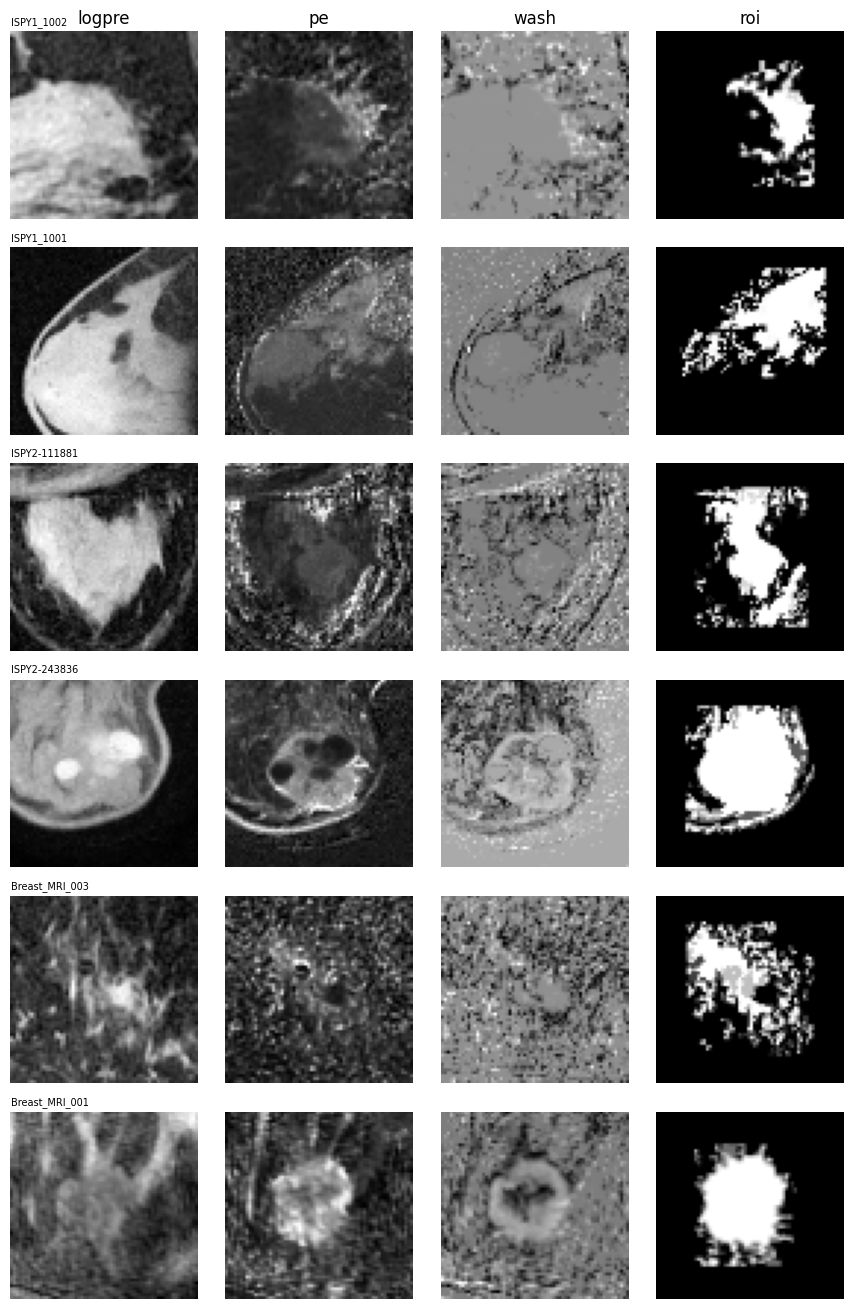

[08:33:14 | 0.06 h elapsed, 10.94 h left] crops on cuda: (1798, 4, 32, 64, 64)


In [10]:
import torch
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
POOL = META[META.split.isin(["train", "val"])].copy()                 # never the test split (D-012)
if not USE_UNLABELED:
    POOL = POOL[POOL.labeled]
if DEBUG:
    POOL = pd.concat([g.sample(min(len(g), 25), random_state=0) for _, g in POOL.groupby(["split", "cohort", "labeled"])])
FILES = mc.cache_files(CACHES, list(POOL.pid))
say(f"1. crops for {len(FILES)} train/val patients ({int(POOL.labeled.sum())} labelled in the pool), grid {CROP}, "
    f"margin {MARGIN_MM} mm, channels {list(m2d.CHANNELS[:4 if ROI_CHANNEL else 3])}")
from concurrent.futures import ProcessPoolExecutor, as_completed
rows, t = [], time.time()
with ProcessPoolExecutor(JOBS) as ex:
    futs = [ex.submit(m2d.make_crop, p, c, f, META.loc[p].to_dict(), mc.clip_of(CACHES[c]["index"], p), tuple(CROP),
                      MARGIN_MM, ROI_CHANNEL) for p, (c, f) in FILES.items()]
    for i, fu in enumerate(as_completed(futs), 1):
        rows.append(fu.result())
        if i % 200 == 0 or i == len(futs):
            say(f"1. crops {i}/{len(futs)} ({(time.time() - t) / 60:.1f} min)")
OKR = [r for r in rows if r["status"] == "ok"]
PIDS = [r["pid"] for r in OKR]
POS = {p: i for i, p in enumerate(PIDS)}
XS = np.stack([r["x"] for r in OKR])
CQC = pd.DataFrame([{k: v for k, v in r.items() if k != "x"} for r in rows])
CQC.to_csv(f"{OUT}/crops_qc.csv", index=False)
print("status:", CQC.status.value_counts().to_dict(), "| array", XS.shape, XS.dtype, f"{XS.nbytes / 1e9:.2f} GB")
if (CQC.status != "ok").any():
    print(CQC.loc[CQC.status != "ok", ["pid", "cohort", "note"]].head(10).to_string(index=False))
okq = CQC[CQC.status == "ok"]
print(okq.groupby("cohort").agg(patients=("pid", "size"), crop_side_mm=("crop_side_mm", "median"),
                               crop_z_mm=("crop_z_mm", "median"), clip_known=("clip_known", "mean")).round(1).to_string())
print(pd.crosstab(okq.cohort, okq.roi_method).to_string())
ch_mean = XS[:: max(1, len(XS) // 300)].astype(np.float32).mean((0, 2, 3, 4))
print("channel means:", dict(zip(m2d.CHANNELS, np.round(ch_mean, 3))))
# a few crops: middle slice of every channel, two patients per cohort
show = [p for c in COH for p in okq[okq.cohort == c].pid.head(2)]
fig, axes = plt.subplots(len(show), XS.shape[1], figsize=(2.2 * XS.shape[1], 2.2 * len(show)), squeeze=False)
for r_, p in enumerate(show):
    x = XS[POS[p]].astype(np.float32)
    for c_ in range(XS.shape[1]):
        axes[r_][c_].imshow(x[c_, x.shape[1] // 2], cmap="gray"); axes[r_][c_].axis("off")
        if r_ == 0: axes[r_][c_].set_title(m2d.CHANNELS[c_])
    axes[r_][0].text(0, -3, p, fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/crop_examples.png", dpi=100); plt.show()
XT = torch.from_numpy(XS).to(DEV)
say(f"crops on {DEV}: {tuple(XT.shape)}")

## 2. SimCLR pretraining of the 3D encoder (GPU, up to `SSL_MAX_MINUTES`)
No labels are used; every train/val patient (incl. Duke without pCR) is a training example; two random augmentations of the same tumour must give similar features.

[08:33:14 | 0.06 h elapsed, 10.94 h left] 2. SimCLR starts on 1798 patients (a line every 10 epochs)
[08:33:38 | 0.07 h elapsed, 10.93 h left] SimCLR epoch 1/300: loss 2.6499 (0.3 min)
[08:35:46 | 0.11 h elapsed, 10.89 h left] SimCLR epoch 11/300: loss 0.1118 (2.4 min)
[08:38:07 | 0.14 h elapsed, 10.86 h left] SimCLR epoch 21/300: loss 0.0732 (4.8 min)
[08:40:35 | 0.19 h elapsed, 10.81 h left] SimCLR epoch 31/300: loss 0.0561 (7.3 min)
[08:43:05 | 0.23 h elapsed, 10.77 h left] SimCLR epoch 41/300: loss 0.0463 (9.8 min)
[08:45:35 | 0.27 h elapsed, 10.73 h left] SimCLR epoch 51/300: loss 0.0404 (12.2 min)
[08:48:05 | 0.31 h elapsed, 10.69 h left] SimCLR epoch 61/300: loss 0.0359 (14.7 min)
[08:50:34 | 0.35 h elapsed, 10.65 h left] SimCLR epoch 71/300: loss 0.0356 (17.2 min)
[08:53:04 | 0.39 h elapsed, 10.61 h left] SimCLR epoch 81/300: loss 0.0299 (19.7 min)
[08:55:33 | 0.44 h elapsed, 10.56 h left] SimCLR epoch 91/300: loss 0.0299 (22.2 min)
[08:58:03 | 0.48 h elapsed, 10.52 h left] Sim

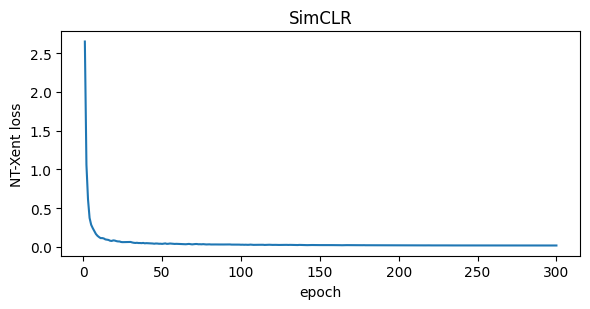

In [11]:
ENC_STATE = None
if RUN_SSL:
    say(f"2. SimCLR starts on {len(XT)} patients (a line every 10 epochs)")
    enc_ssl, HIST = m2n.train_simclr(XT, epochs=3 if DEBUG else SSL_EPOCHS, batch=SSL_BATCH,
                                     max_minutes=SSL_MAX_MINUTES, lr=SSL_LR, temp=TEMPERATURE, width=WIDTH, seed=SEED, say=say)
    ENC_STATE = {k: v.detach().cpu() for k, v in enc_ssl.state_dict().items()}
    torch.save(ENC_STATE, f"{OUT}/encoder_ssl.pt")
    HIST.to_csv(f"{OUT}/ssl_loss.csv", index=False)
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(HIST.epoch + 1, HIST.loss); ax.set_xlabel("epoch"); ax.set_ylabel("NT-Xent loss"); ax.set_title("SimCLR")
    plt.tight_layout(); plt.savefig(f"{OUT}/ssl_loss.png", dpi=120); plt.show()
else:
    w = SSL_WEIGHTS
    if w == "auto":
        hits = sorted(glob.glob("/kaggle/input/**/encoder_ssl.pt", recursive=True))
        w = hits[0] if hits else ""
    if w:
        ENC_STATE = torch.load(w, map_location="cpu")
        say(f"2. SimCLR skipped: encoder weights from {w}")
    else:
        say("2. SimCLR skipped and no weights given: fine-tuning starts from random weights")

## 3. Linear probes: SimCLR features vs random weights, with and without the clinical data

In [12]:
LAB = META[META.labeled & META.split.isin(["train", "val"]) & META.pid.isin(PIDS)].reset_index(drop=True)
LAB["label"] = LAB.pCR.astype(int)
TR, VA = LAB[LAB.split == "train"].reset_index(drop=True), LAB[LAB.split == "val"].reset_index(drop=True)
Y = TR.label.to_numpy(int)
IDX_TR, IDX_VA = np.array([POS[p] for p in TR.pid]), np.array([POS[p] for p in VA.pid])
CLIN_TR = pd.concat([mc.clinical_frame(TR), TR[["log_bbox_vol"]]], axis=1)   # clinical + tumour size
CLIN_VA = pd.concat([mc.clinical_frame(VA), VA[["log_bbox_vol"]]], axis=1)
FOLDS = mc.make_folds(TR.cohort + "_" + TR.label.astype(str), 2 if DEBUG else PROBE_REPEATS, seed=SEED)
say(f"3. linear probes: train {len(TR)} ({Y.sum()} pCR), val {len(VA)}")
MODELS = {}
lk = m2e.lookup_preds(TR, VA, FOLDS)
MODELS["subtype lookup"] = {"oof": lk[0], "fold_auc": lk[1], "val": lk[2]}
torch.manual_seed(SEED)
enc_rand = m2n.Encoder(XT.shape[1], WIDTH).to(DEV)
EMB = {"random": (m2n.embed(enc_rand, XT, IDX_TR), m2n.embed(enc_rand, XT, IDX_VA))}
if ENC_STATE is not None:
    enc_p = m2n.Encoder(XT.shape[1], WIDTH); enc_p.load_state_dict(ENC_STATE); enc_p = enc_p.to(DEV)
    EMB["SSL"] = (m2n.embed(enc_p, XT, IDX_TR), m2n.embed(enc_p, XT, IDX_VA))
    np.savez_compressed(f"{OUT}/embeddings_ssl.npz", pid=np.array(list(TR.pid) + list(VA.pid), dtype=str), emb=np.r_[EMB["SSL"][0], EMB["SSL"][1]])
probes = [("clinical (LR)", CLIN_TR.to_numpy(float), CLIN_VA.to_numpy(float))]
for k_, (etr, eva) in EMB.items():
    probes += [(f"{k_} probe: image only", etr, eva),
               (f"{k_} probe: clinical + image", np.hstack([CLIN_TR.to_numpy(float), etr]), np.hstack([CLIN_VA.to_numpy(float), eva]))]
for name, A, B in probes:
    r = mc.cv_and_refit(A, Y, FOLDS, B, kinds=("lr",), jobs=JOBS, seed=SEED)["lr"]
    MODELS[name] = r
    say(f"3. {name}: cv {np.nanmean(r['fold_auc']):.3f} | oof {mc.auc(Y, r['oof']):.3f} "
        f"(within subtype {mc.within_auc(Y, r['oof'], TR.subtype):.3f}) | val {mc.auc(VA.label, r['val']):.3f}")

[09:47:41 | 1.30 h elapsed, 9.70 h left] 3. linear probes: train 1098 (321 pCR), val 177
[09:48:01 | 1.31 h elapsed, 9.69 h left] 3. clinical (LR): cv 0.700 | oof 0.695 (within subtype 0.588) | val 0.652
[09:48:13 | 1.31 h elapsed, 9.69 h left] 3. random probe: image only: cv 0.546 | oof 0.538 (within subtype 0.544) | val 0.546
[09:48:26 | 1.32 h elapsed, 9.68 h left] 3. random probe: clinical + image: cv 0.674 | oof 0.675 (within subtype 0.583) | val 0.656
[09:48:36 | 1.32 h elapsed, 9.68 h left] 3. SSL probe: image only: cv 0.579 | oof 0.575 (within subtype 0.574) | val 0.621
[09:48:46 | 1.32 h elapsed, 9.68 h left] 3. SSL probe: clinical + image: cv 0.675 | oof 0.676 (within subtype 0.589) | val 0.713


## 4. Fine-tuning: image only, and with the clinical data via FiLM (GPU, ~2 min per fold)

In [13]:
FT_FOLDS = mc.make_folds(TR.cohort + "_" + TR.label.astype(str), 1 if DEBUG else FT_REPEATS, seed=SEED + 100)
FT_LOG = []
for mode in FT_MODES:
    reps = max(r for r, *_ in FT_FOLDS) + 1
    oof, vals, fa = np.full((reps, len(TR)), np.nan), [], []
    t = time.time()
    for r, f, a, b in FT_FOLDS:
        if budget_left() < 0.5:
            say(f"4. time budget nearly used: {mode} stops after {len(fa)} folds"); break
        ce = m2n.ClinEnc().fit(CLIN_TR.iloc[a])
        (pb, pv), ep, ain = m2n.finetune_fold(
            XT, ENC_STATE, WIDTH, IDX_TR[a], Y[a], ce.transform(CLIN_TR.iloc[a]),
            [(IDX_TR[b], ce.transform(CLIN_TR.iloc[b])), (IDX_VA, ce.transform(CLIN_VA))], film=(mode == "film"),
            epochs=3 if DEBUG else FT_EPOCHS, patience=FT_PATIENCE, batch=FT_BATCH, lr_enc=LR_ENC, lr_head=LR_HEAD,
            seed=SEED + 10 * r + f)
        oof[r, b], vals = pb, vals + [pv]
        fa.append(mc.auc(Y[b], pb))
        FT_LOG.append({"mode": mode, "repeat": r, "fold": f, "best_epoch": ep, "inner_auc": ain, "fold_auc": fa[-1]})
        say(f"4. {mode} repeat {r} fold {f}: fold AUC {fa[-1]:.3f} (best epoch {ep}, inner {ain:.3f}) "
            f"| {(time.time() - t) / 60:.1f} min")
    if fa:
        name = "fine-tuned + clinical (FiLM)" if mode == "film" else "fine-tuned: image only"
        MODELS[name] = {"oof": np.nanmean(oof, 0), "fold_auc": fa, "val": np.mean(vals, 0)}
        o = MODELS[name]["oof"]; okm = ~np.isnan(o)
        say(f"4. {name}: cv {np.mean(fa):.3f} | oof {mc.auc(Y[okm], o[okm]):.3f} | val {mc.auc(VA.label, MODELS[name]['val']):.3f}")
pd.DataFrame(FT_LOG).to_csv(f"{OUT}/finetune_folds.csv", index=False)

[09:49:27 | 1.33 h elapsed, 9.67 h left] 4. film repeat 0 fold 0: fold AUC 0.655 (best epoch 3, inner 0.717) | 0.7 min
[09:50:19 | 1.35 h elapsed, 9.65 h left] 4. film repeat 0 fold 1: fold AUC 0.634 (best epoch 6, inner 0.732) | 1.5 min
[09:50:58 | 1.36 h elapsed, 9.64 h left] 4. film repeat 0 fold 2: fold AUC 0.731 (best epoch 2, inner 0.739) | 2.2 min
[09:51:51 | 1.37 h elapsed, 9.63 h left] 4. film repeat 0 fold 3: fold AUC 0.635 (best epoch 6, inner 0.780) | 3.1 min
[09:52:27 | 1.38 h elapsed, 9.62 h left] 4. film repeat 0 fold 4: fold AUC 0.729 (best epoch 1, inner 0.685) | 3.7 min
[09:54:17 | 1.41 h elapsed, 9.59 h left] 4. film repeat 1 fold 0: fold AUC 0.596 (best epoch 23, inner 0.704) | 5.5 min
[09:55:40 | 1.44 h elapsed, 9.56 h left] 4. film repeat 1 fold 1: fold AUC 0.708 (best epoch 15, inner 0.768) | 6.9 min
[09:56:19 | 1.45 h elapsed, 9.55 h left] 4. film repeat 1 fold 2: fold AUC 0.654 (best epoch 2, inner 0.777) | 7.6 min
[09:56:56 | 1.46 h elapsed, 9.54 h left] 4. fi

## 5. Summary: does the image add to the clinical data?

                         model  cv_auc  cv_sd  oof_auc  oof_within_subtype  oof_within_cohort  val_auc  val_ci_lo  val_ci_hi  val_within_subtype  val_within_cohort  oof_ispy1  oof_ispy2  oof_duke  val_ispy1  val_ispy2  val_duke  oof_vs_lookup  oof_vs_lookup_p
                 clinical (LR)   0.700  0.033    0.695               0.588              0.686    0.652      0.566      0.737               0.544              0.655      0.751      0.683     0.718      0.690      0.648     0.674          0.065            0.000
   SSL probe: clinical + image   0.675  0.039    0.676               0.589              0.674    0.713      0.632      0.791               0.642              0.728      0.696      0.674     0.652      0.690      0.733     0.723          0.047            0.006
random probe: clinical + image   0.674  0.031    0.675               0.583              0.670    0.656      0.566      0.743               0.572              0.659      0.717      0.670     0.664      0.624      0.655   

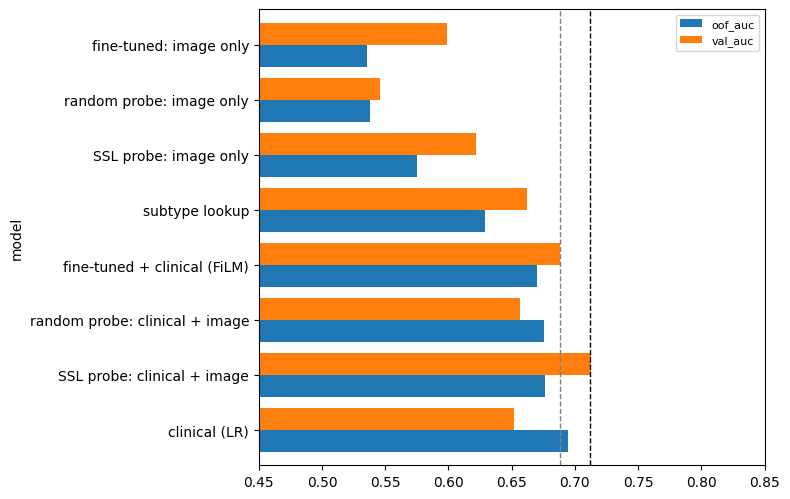

                               model   n  pcr   auc  ci_lo  ci_hi  auprc  brier   ece  sens@90spec  ppv@90spec  npv@90spec  diff_vs_ref  delong_ci_lo  delong_ci_hi  delong_p  boot_p
             B1 LR (clinical + size) 177   53 0.653  0.566  0.740  0.448  0.196 0.041        0.245       0.520       0.737       -0.009        -0.077         0.058     0.787   0.772
                      subtype lookup 177   53 0.662  0.579  0.745  0.411  0.198 0.061        0.000         NaN       0.701          NaN           NaN           NaN       NaN     NaN
            F2 fusion v1 (old cache) 177   53 0.690  0.603  0.777  0.516  0.194 0.080        0.283       0.556       0.747        0.028        -0.001         0.057     0.058   0.068
               step15: clinical (LR) 177   53 0.652  0.565  0.739  0.444  0.197 0.045        0.226       0.500       0.732       -0.010        -0.075         0.055     0.764   0.749
 step15: SSL probe: clinical + image 177   53 0.713  0.631  0.794  0.489  0.187 0.041     

In [14]:
for k_, m in MODELS.items():   # a model stopped by the time budget has NaN OOF for some patients: fill with the median
    if np.isnan(m["oof"]).any():
        m["oof"] = np.where(np.isnan(m["oof"]), np.nanmedian(m["oof"]), m["oof"])
PAIRS = [("random weights -> SimCLR (image only)", "random probe: image only", "SSL probe: image only"),
         ("random weights -> SimCLR (clinical + image)", "random probe: clinical + image", "SSL probe: clinical + image"),
         ("clinical -> clinical + SimCLR image (probe)", "clinical (LR)", "SSL probe: clinical + image"),
         ("SimCLR probe -> fine-tuned (image only)", "SSL probe: image only", "fine-tuned: image only"),
         ("clinical -> fine-tuned + clinical (FiLM)", "clinical (LR)", "fine-tuned + clinical (FiLM)"),
         ("probe clinical + image -> FiLM", "SSL probe: clinical + image", "fine-tuned + clinical (FiLM)"),
         ("subtype lookup -> clinical", "subtype lookup", "clinical (LR)")]
STACK = {"m2_probe_img": "SSL probe: image only", "m2_probe_clin": "SSL probe: clinical + image",
         "m2_ft_img": "fine-tuned: image only", "m2_film": "fine-tuned + clinical (FiLM)"}
note = (f"Train {len(TR)} / val {len(VA)}. Probes: {2 if DEBUG else PROBE_REPEATS} x 5-fold CV (OOF = every train "
        f"patient) + refit on train for val. Fine-tuning: {1 if DEBUG else FT_REPEATS} x 5-fold outer CV, early stopping on an "
        f"inner 15% split; val = mean of the fold models. Caches: " + ", ".join(f"{c} {v['kind']}" for c, v in CACHES.items()))
RES, CMPS = m2e.report(TR, VA, MODELS, PAIRS, OUT, "Step 15 results: kinetic-map 3D encoder", note, STACK)
print(RES.round(3).to_string(index=False))
print("\nPaired comparisons (b - a, same patients):")
print(CMPS.round(3).to_string(index=False))
r = RES.set_index("model")[["oof_auc", "val_auc"]]
ax = r.plot.barh(figsize=(8, 0.45 * len(r) + 1.5), width=0.8)
for x in (0.688, 0.712):
    ax.axvline(x, ls="--", lw=1, color="k" if x > 0.7 else "gray")
ax.set_xlim(0.45, 0.85); ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT}/auc_by_model.png", dpi=120); plt.show()

CMP = None
try:
    def as_preds(col):
        V = pd.read_csv(f"{OUT}/val_preds.csv", dtype={"pid": str})
        return V[["pid", "cohort", "label"]].assign(prob=V[col].values)
    preds = {"B1 LR (clinical + size)": B1_VAL, "subtype lookup": as_preds("subtype lookup"),
             "F2 fusion v1 (old cache)": F2_V1}
    preds.update({f"{STEP}: {k_}": as_preds(k_) for k_ in ("clinical (LR)", "SSL probe: clinical + image",
                                                            "fine-tuned + clinical (FiLM)") if k_ in MODELS})
    CMP = compare(preds, "subtype lookup")
    print(CMP.round(3).to_string(index=False))
    CMP.to_csv(f"{OUT}/comparison_vs_team.csv", index=False)
    ours = {k_: v for k_, v in preds.items() if k_.startswith(STEP)}
    print("\nper subtype (val):"); print(subtype_wide(ours).to_string())
    print("\nper cohort (val):"); print(subtype_wide(ours, by="cohort").to_string())
except Exception as e:
    print("comparison with the team's models skipped:", type(e).__name__, e)

## 6. Results file
`RESULTS_step15.md`, `stack_inputs.csv` (OOF scores for step 14), `encoder_ssl.pt`.

In [15]:
txt = open(f"{OUT}/RESULTS.md").read()
if CMP is not None:
    txt += "\n## Best models vs the team's models (val, paired DeLong vs the subtype lookup)\n\n" + mc.md_table(CMP) + "\n"
open(f"{OUT}/RESULTS_step15.md", "w").write(txt)
say(f"wrote {OUT}/RESULTS_step15.md and {OUT}/stack_inputs.csv (attach this notebook's output to step 14)")

[10:09:22 | 1.67 h elapsed, 9.33 h left] wrote /kaggle/working/results/vaib/step15/RESULTS_step15.md and /kaggle/working/results/vaib/step15/stack_inputs.csv (attach this notebook's output to step 14)


In [16]:
# ==== PUSH the small result files to the vaib branch (results/<PERSON>/...) ====
if PUSH_RESULTS and not _tok:
    print("PUSH_RESULTS needs the GITHUB_TOKEN secret; download results/ from the Output tab instead")
elif PUSH_RESULTS and not DEBUG:
    git("config", "user.name", f"Person {PERSON} (Kaggle)")
    git("config", "user.email", "kaggle@users.noreply.github.com")
    for attempt in range(3):
        git("fetch", "--quiet", "--depth", "1", "origin", f"+refs/heads/{GIT_TAG}:refs/remotes/origin/{GIT_TAG}")
        git("checkout", "--quiet", "-f", "-B", GIT_TAG, f"origin/{GIT_TAG}")
        shutil.copytree(f"/kaggle/working/results/{PERSON}", f"results/{PERSON}", dirs_exist_ok=True)
        git("add", f"results/{PERSON}")
        print(git("commit", "-m", f"results: {PERSON} {NOTEBOOK_NAME} ({GIT_TAG})"))
        try:
            git("push", "--quiet", "origin", GIT_TAG); print("pushed to", GIT_TAG); break
        except RuntimeError as e:
            print(f"push attempt {attempt + 1} failed:", e)
    else:
        print("NOT pushed: download results/ from the Output tab")